# JS13 - Praktikum 3: Regresi dengan Keras
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Regresi non-linier menggunakan Multi-Layer Perceptron (Keras) serta analisis pengaruh learning rate terhadap kecepatan konvergensi MSE loss.


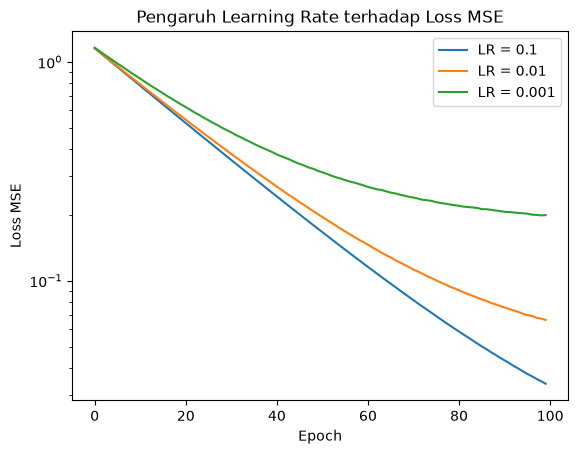

In [1]:
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90, 100, 120, 140],
    'harga': [500, 600, 700, 800, 900, 1020, 1250, 1480]
})

X_s = StandardScaler().fit_transform(data[['luas']])
y_s = StandardScaler().fit_transform(data[['harga']])

for lr in [0.1, 0.01, 0.001]:
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    h = m.fit(X_s, y_s, epochs=100, verbose=0)
    plt.plot(h.history['loss'], label=f'LR = {lr}')

plt.title("Pengaruh Learning Rate terhadap Loss MSE")
plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("Loss MSE")
plt.legend()
plt.show()
